# Phase 2 · Statistical Analysis (Q1–Q5) & Synthesis
**Nhóm CSC17104:** Trần Nhật Dương (Q1–Q2) · Nguyễn Mạnh Hà (Q3–Q4) · Hoàng Công Lý (Q5)

Notebook tổng hợp phân tích thống kê non-ML theo từng giai đoạn chủ đề, bao phủ **5/6 tiêu chí độ sâu (`D2, D3, D4, D5, D6`)**. Quy ước chung từ `coupon_project.stats`: tỷ lệ theo `%`, chênh lệch theo điểm % (`pp`), gắn cờ `*` khi `n < 30`, và chỉ kết luận **mối liên hệ trong khảo sát**.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coupon_project.data import RAW_CSV_PATH, load_raw_data, row_count_log, save_table
from coupon_project.features import (
    COUPON_FREQUENCY, COUPONS, DESTINATIONS, EXPIRATION_ORDER, FREQUENCIES,
    PASSENGERS, TIME_ORDER, TRAVEL_BAND_ORDER, add_travel_time_band,
    build_respondent_id, check_journey_flags, matched_frequency,
)
from coupon_project.plotting import plot_bars_ci, plot_heatmap, save_figure, set_style
from coupon_project.stats import (
    MIN_N, cluster_diff_ci, cluster_rates_ci, contrasts,
    pivot_expiration, rate_table, standardized_contrast,
)

df = load_raw_data(RAW_CSV_PATH)
print(row_count_log(len(df), len(df), "Phase 2 raw load (no rows dropped)"))

Phase 2 raw load (no rows dropped): 12,684 -> 12,684 rows (delta +0)


---
## Phase 2.1 · Bối cảnh hành trình & Thời hạn coupon *(Trần Nhật Dương — Q1 & Q2)*

### Q1 · Khoảng cách & hướng di chuyển (`D3, D4, D5`)
- **Motivation:** Hỗ trợ app dẫn đường chọn bán kính và hướng hiển thị coupon phù hợp, tránh buộc tài xế đi vòng xa.
- **Phương pháp:** Kiểm tra cờ `GEQ5/15/25`, tạo biến `travel_time_band` (`D3`), phân tầng theo `destination` & `coupon` (`D4`), tính 95% bootstrap CI (`D5`) + độ nhạy loại `74` dòng trùng.

In [2]:
q1_df = add_travel_time_band(df)
print("Audit flags:", check_journey_flags(q1_df))

dist_overall = contrasts(q1_df, [], "travel_time_band", "5-<15 min", ">=25 min", key="q1_overall")
dist_dest = contrasts(q1_df, ["destination"], "travel_time_band", "5-<15 min", ">=25 min", key="q1_dest")
dist_coupon = contrasts(q1_df, ["coupon"], "travel_time_band", "5-<15 min", ">=25 min", key="q1_coupon")
dir_overall = contrasts(q1_df, [], "direction_same", 1, 0, key="q1_dir_overall")
dir_strata = contrasts(q1_df, ["destination", "travel_time_band"], "direction_same", 1, 0, key="q1_dir_strata")
dir_dest = contrasts(q1_df, ["destination"], "direction_same", 1, 0, key="q1_dir_dest")

display(rate_table(q1_df, ["travel_time_band"], ci_method="bootstrap"))
display(dist_overall)
display(dist_dest)
display(dist_coupon)
display(dir_overall)
display(dir_dest)
display(dir_strata)

df_dedup = add_travel_time_band(df.drop_duplicates())
print(row_count_log(len(df), len(df_dedup), "Sensitivity drop exact duplicates"))
display(contrasts(df_dedup, [], "travel_time_band", "5-<15 min", ">=25 min", key="q1_dedup"))

save_table(pd.concat([
    dist_overall.assign(scope="overall"), dist_dest.assign(scope="destination"), dist_coupon.assign(scope="coupon"),
], ignore_index=True), "q1_distance_contrasts")
save_table(pd.concat([
    dir_overall.assign(scope="overall"), dir_dest.assign(scope="destination"), dir_strata.assign(scope="destination_band"),
], ignore_index=True), "q1_direction_contrasts")

Audit flags: {'n_rows': 12684, 'geq5_always_one': True, 'invalid_geq_hierarchy_count': 0, 'direction_complement_ok': True}


,travel_time_band,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_n
0,5-<15 min,5562,3416,61.42,60.09,62.68,False
1,15-<25 min,5611,3146,56.07,54.75,57.41,False
2,>=25 min,1511,648,42.89,40.24,45.34,False


,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,5-<15 min,>=25 min,3416,648,5562,1511,61.42,42.89,18.53,15.69,21.38,False,ok


,destination,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,Home,5-<15 min,>=25 min,990,185,1792,472,55.25,39.19,16.05,11.20,21.21,False,ok
1,No Urgent Place,5-<15 min,>=25 min,1694,0,2639,0,64.19,NaN,NaN,NaN,NaN,True,no_common_support
2,Work,5-<15 min,>=25 min,732,463,1131,1039,64.72,44.56,20.16,16.13,24.28,False,ok


,coupon,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,Bar,5-<15 min,>=25 min,299,197,679,510,44.04,38.63,5.41,-0.28,11.19,False,ok
1,Carry out & Take away,5-<15 min,>=25 min,657,194,873,265,75.26,73.21,2.05,-3.75,8.27,False,ok
2,Coffee House,5-<15 min,>=25 min,1054,107,1923,310,54.81,34.52,20.29,14.51,26.11,False,ok
3,Restaurant(20-50),5-<15 min,>=25 min,246,49,547,116,44.97,42.24,2.73,-7.14,12.71,False,ok
4,Restaurant(<20),5-<15 min,>=25 min,1160,101,1540,310,75.32,32.58,42.74,37.13,48.56,False,ok


,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,1,0,1586,5624,2724,9960,58.22,56.47,1.76,-0.33,3.85,False,ok


,destination,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,Home,1,0,912,727,1524,1713,59.84,42.44,17.40,13.85,20.93,False,ok
1,No Urgent Place,1,0,0,3982,0,6283,NaN,63.38,NaN,NaN,NaN,True,no_common_support
2,Work,1,0,674,915,1200,1964,56.17,46.59,9.58,6.26,13.21,False,ok


,destination,travel_time_band,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,Home,5-<15 min,1,0,692,298,1179,613,58.69,48.61,10.08,5.09,15.03,False,ok
1,Home,15-<25 min,1,0,220,244,345,628,63.77,38.85,24.91,18.47,30.81,False,ok
2,Home,>=25 min,1,0,0,185,0,472,NaN,39.19,NaN,NaN,NaN,True,no_common_support
3,No Urgent Place,5-<15 min,1,0,0,1694,0,2639,NaN,64.19,NaN,NaN,NaN,True,no_common_support
4,No Urgent Place,15-<25 min,1,0,0,2288,0,3644,NaN,62.79,NaN,NaN,NaN,True,no_common_support
5,Work,5-<15 min,1,0,496,236,800,331,62.00,71.30,-9.30,-14.51,-3.44,False,ok
6,Work,15-<25 min,1,0,178,216,400,594,44.50,36.36,8.14,1.88,14.14,False,ok
7,Work,>=25 min,1,0,0,463,0,1039,NaN,44.56,NaN,NaN,NaN,True,no_common_support


Sensitivity drop exact duplicates: 12,684 -> 12,610 rows (delta -74)


,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,5-<15 min,>=25 min,3407,614,5551,1463,61.38,41.97,19.41,16.56,22.29,False,ok


WindowsPath('C:/Users/MY MSI/Desktop/Môn học/Chuyên ngành/Data Science Programming/Project/reports/tables/q1_direction_contrasts.csv')

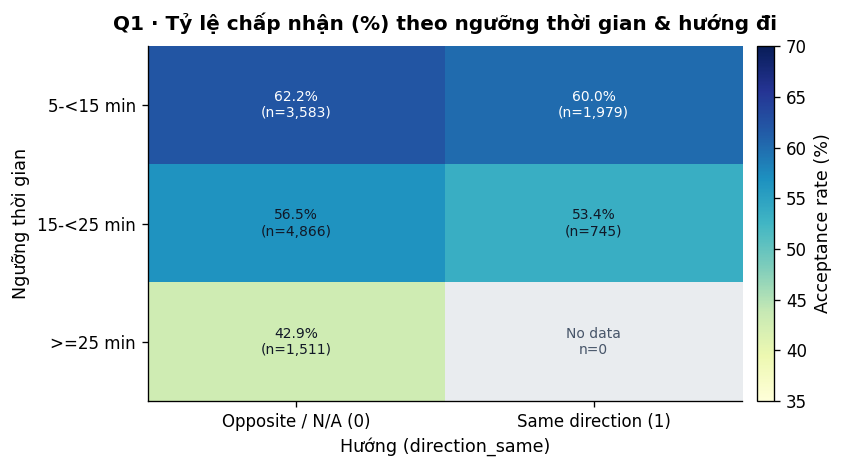

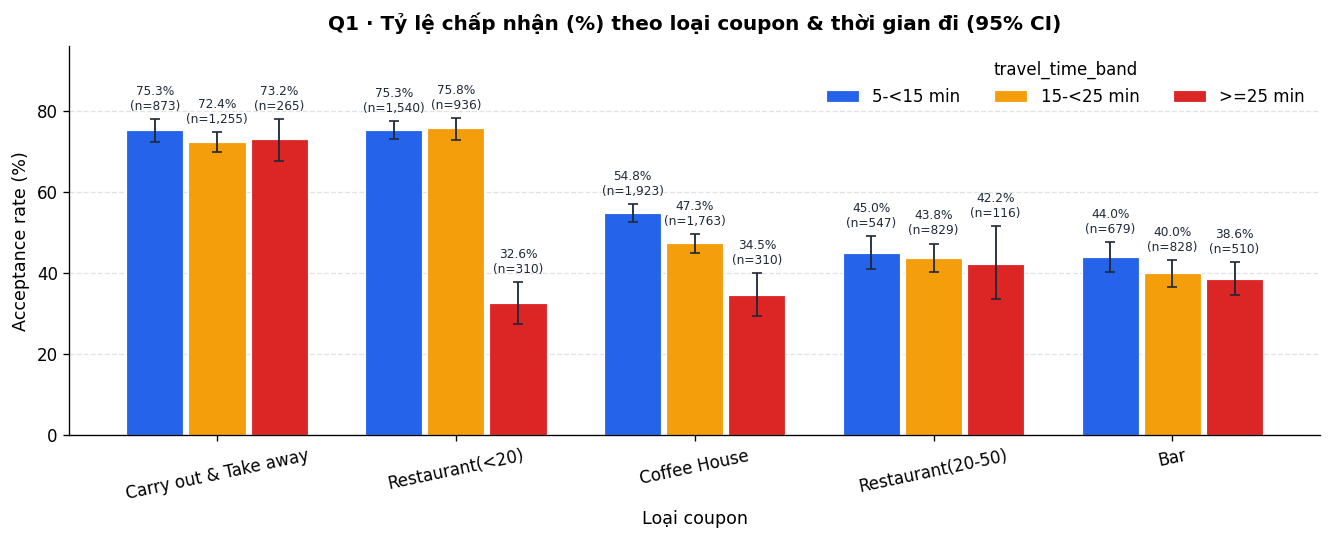

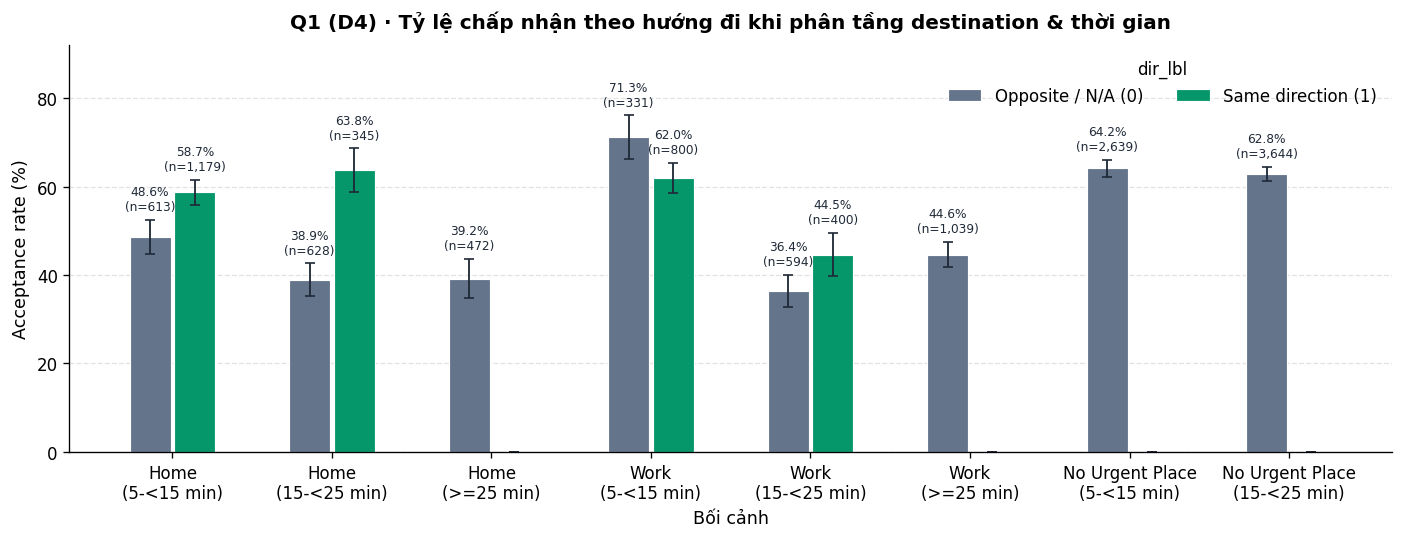

In [3]:
col_map = {0: "Opposite / N/A (0)", 1: "Same direction (1)"}
q1_hm_rate = q1_df.pivot_table("Y", "travel_time_band", "direction_same", "mean", observed=False).mul(100).rename(columns=col_map)
q1_hm_cnt = q1_df.pivot_table("Y", "travel_time_band", "direction_same", "count", observed=False).fillna(0).astype(int).rename(columns=col_map)
plot_heatmap(
    q1_hm_rate, q1_hm_cnt,
    "Q1 · Tỷ lệ chấp nhận (%) theo ngưỡng thời gian & hướng đi",
    "Hướng (direction_same)", "Ngưỡng thời gian", "Acceptance rate (%)",
    out_name="q1_fig1_heatmap_travel_time_direction", vmin=35, vmax=70, figsize=(7.4, 4.0),
)
plt.show()

coupon_ord_q1 = ["Carry out & Take away", "Restaurant(<20)", "Coffee House", "Restaurant(20-50)", "Bar"]
plot_bars_ci(
    rate_table(q1_df, ["coupon", "travel_time_band"], ci_method="bootstrap"), "coupon", "travel_time_band",
    coupon_ord_q1, TRAVEL_BAND_ORDER,
    "Q1 · Tỷ lệ chấp nhận (%) theo loại coupon & thời gian đi (95% CI)", "Loại coupon",
    out_name="q1_fig2_grouped_bar_coupon_travel_time",
    colors=["#2563EB", "#F59E0B", "#DC2626"], figsize=(11.2, 4.6), ylim=(0, 96), rotate_xticks=12,
)
plt.show()

q1_dd = rate_table(q1_df, ["destination", "travel_time_band", "direction_same"], ci_method="bootstrap")
q1_dd["stratum"] = q1_dd["destination"].astype(str) + "\n(" + q1_dd["travel_time_band"].astype(str) + ")"
q1_dd["dir_lbl"] = q1_dd["direction_same"].map(col_map)
stratum_ord = [
    "Home\n(5-<15 min)", "Home\n(15-<25 min)", "Home\n(>=25 min)",
    "Work\n(5-<15 min)", "Work\n(15-<25 min)", "Work\n(>=25 min)",
    "No Urgent Place\n(5-<15 min)", "No Urgent Place\n(15-<25 min)",
]
plot_bars_ci(
    q1_dd, "stratum", "dir_lbl", stratum_ord, ["Opposite / N/A (0)", "Same direction (1)"],
    "Q1 (D4) · Tỷ lệ chấp nhận theo hướng đi khi phân tầng destination & thời gian", "Bối cảnh",
    out_name="q1_fig3_stratified_destination_direction",
    colors=["#64748B", "#059669"], figsize=(11.8, 4.6), ylim=(0, 92),
)
plt.show()

**Kết luận Q1 & Hạn chế:**
- Toàn mẫu, `5–<15 min` cao nhất (**61,42%**, `n=5.562`) > `15–<25 min` (**56,07%**, `n=5.611`) > `≥25 min` (**42,89%**, `n=1.511`); chênh gần–xa **+18,53 điểm %** (sau khi loại 74 dòng trùng là **+19,41 pp**).
- Độ nhạy khác nhau theo coupon: `Restaurant(<20)` sụt **+42,74 pp** (`75,32%` → `32,58%`) và `Coffee House` giảm **+20,29 pp**, trong khi `Carry out & Take away` giữ phẳng (**73,21%** ở `≥25 min`, chênh chỉ `+2,05 pp`).
- **Hiệu ứng nhiễu `destination`:** Thô toàn mẫu `direction_same=1` chỉ nhỉnh hơn `+1,76 pp` (CI cắt qua 0) do toàn bộ `6.283` dòng `No Urgent Place` mang giá trị `0`; khi giữ cố định `Home`, đi cùng hướng tăng tới **+17,40 pp** (`15–<25 min` đạt **+24,91 pp**), còn `Work` `5–<15 min` đảo chiều (`-9,30 pp`).
- **Hạn chế:** Cờ `GEQ` là ngưỡng rời rạc (không phải GPS), có ô rỗng cấu trúc (`No Urgent Place` không có `≥25 min` hay `direction_same=1`), bootstrap chưa tách cụm người trả lời.

### Q2 · Thời hạn `2h` vs `1d` theo khung giờ trong ngày & loại coupon (`D2, D4, D5`)
- **Motivation:** Cân nhắc phát coupon ngắn hạn (`2h`) hay linh hoạt (`1d`) theo khung giờ và loại hình dịch vụ.
- **Phương pháp:** `pivot_table` & `melt` (`time × expiration`, `D2`), phân tầng `coupon` & `time × coupon` (`D4`), tính 95% bootstrap CI (`D5`). *(`time` là 5 mốc giờ trong ngày, không phải chuỗi nhiều ngày.)*

In [4]:
q2_rate_p, q2_cnt_p, q2_long = pivot_expiration(df)
display(q2_rate_p)
display(q2_cnt_p)
display(q2_long.head(4))
save_table(q2_long, "q2_time_expiration_pivot")

q2_overall = contrasts(df, [], "expiration", "1d", "2h", key="q2_overall")
q2_time_diff = contrasts(df, ["time"], "expiration", "1d", "2h", key="q2_time")
q2_coupon_diff = contrasts(df, ["coupon"], "expiration", "1d", "2h", key="q2_coupon")
q2_tc_diff = contrasts(df, ["time", "coupon"], "expiration", "1d", "2h", key="q2_tc")

display(q2_overall)
display(q2_time_diff)
display(q2_coupon_diff)
print("Giải thích nghịch lý lúc 10AM (cơ cấu % coupon trong 1d vs 2h):")
display(pd.crosstab(df.loc[df["time"] == "10AM", "coupon"], df.loc[df["time"] == "10AM", "expiration"], normalize="columns").mul(100).round(1))
display(q2_tc_diff[q2_tc_diff["time"] == "10AM"])
save_table(pd.concat([q2_overall.assign(scope="overall"), q2_time_diff.assign(scope="time"), q2_coupon_diff.assign(scope="coupon")], ignore_index=True), "q2_expiry_contrasts")

expiration,2h,1d,diff_1d_minus_2h_pp
time,,,
7AM,37.51,58.29,20.78
10AM,61.76,59.75,-2.01
2PM,55.85,71.77,15.92
6PM,54.53,61.82,7.29
10PM,36.90,63.03,26.13


expiration,2h,1d
time,,
7AM,1229,1935
10AM,1229,1046
2PM,709,1300
6PM,1491,1739
10PM,935,1071


,time,expiration,rate_pct,n
0,7AM,2h,37.51,1229
1,10AM,2h,61.76,1229
2,2PM,2h,55.85,709
3,6PM,2h,54.53,1491


,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,1d,2h,4436,2774,7091,5593,62.56,49.6,12.96,11.27,14.7,False,ok


,time,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,10AM,1d,2h,625,759,1046,1229,59.75,61.76,-2.01,-5.78,2.24,False,ok
1,10PM,1d,2h,675,345,1071,935,63.03,36.90,26.13,22.03,30.32,False,ok
2,2PM,1d,2h,933,396,1300,709,71.77,55.85,15.92,11.52,20.20,False,ok
3,6PM,1d,2h,1075,813,1739,1491,61.82,54.53,7.29,3.85,10.67,False,ok
4,7AM,1d,2h,1128,461,1935,1229,58.29,37.51,20.78,17.11,24.25,False,ok


,coupon,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,Bar,1d,2h,641,186,1556,461,41.20,40.35,0.85,-4.30,5.73,False,ok
1,Carry out & Take away,1d,2h,1138,622,1456,937,78.16,66.38,11.78,8.21,15.48,False,ok
2,Coffee House,1d,2h,1033,962,1769,2227,58.39,43.20,15.20,12.03,18.19,False,ok
3,Restaurant(20-50),1d,2h,498,160,956,536,52.09,29.85,22.24,17.46,27.50,False,ok
4,Restaurant(<20),1d,2h,1126,844,1354,1432,83.16,58.94,24.22,20.96,27.40,False,ok


Giải thích nghịch lý lúc 10AM (cơ cấu % coupon trong 1d vs 2h):


expiration,1d,2h
coupon,,
Bar,36.1,5.4
Carry out & Take away,14.2,29.9
Coffee House,32.2,45.7
Restaurant(20-50),6.7,3.4
Restaurant(<20),10.7,15.5


,time,coupon,group_a,group_b,accepted_a,accepted_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_n,status
0,10AM,Bar,1d,2h,150,11,378,66,39.68,16.67,23.02,12.79,32.78,False,ok
1,10AM,Carry out & Take away,1d,2h,118,245,149,368,79.19,66.58,12.62,4.26,20.58,False,ok
2,10AM,Coffee House,1d,2h,221,355,337,562,65.58,63.17,2.41,-3.82,8.70,False,ok
3,10AM,Restaurant(20-50),1d,2h,48,21,70,42,68.57,50.00,18.57,0.46,36.19,False,ok
4,10AM,Restaurant(<20),1d,2h,88,127,112,191,78.57,66.49,12.08,1.95,21.84,False,ok


WindowsPath('C:/Users/MY MSI/Desktop/Môn học/Chuyên ngành/Data Science Programming/Project/reports/tables/q2_expiry_contrasts.csv')

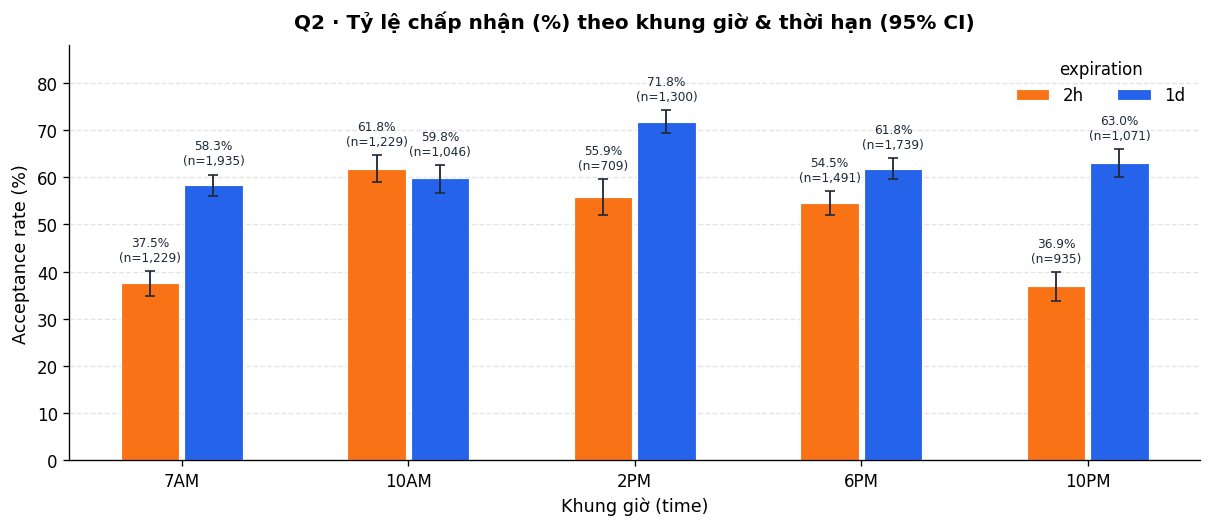

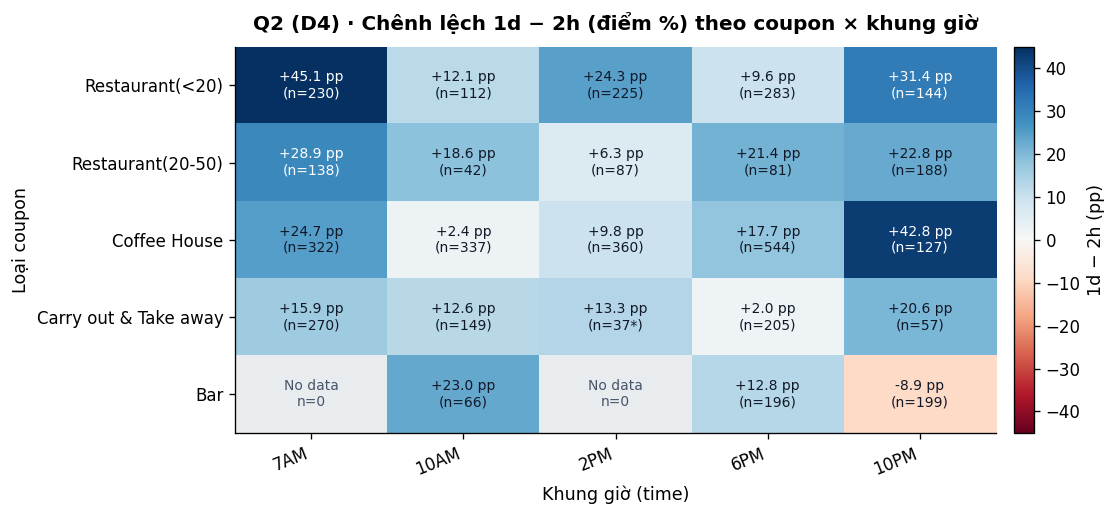

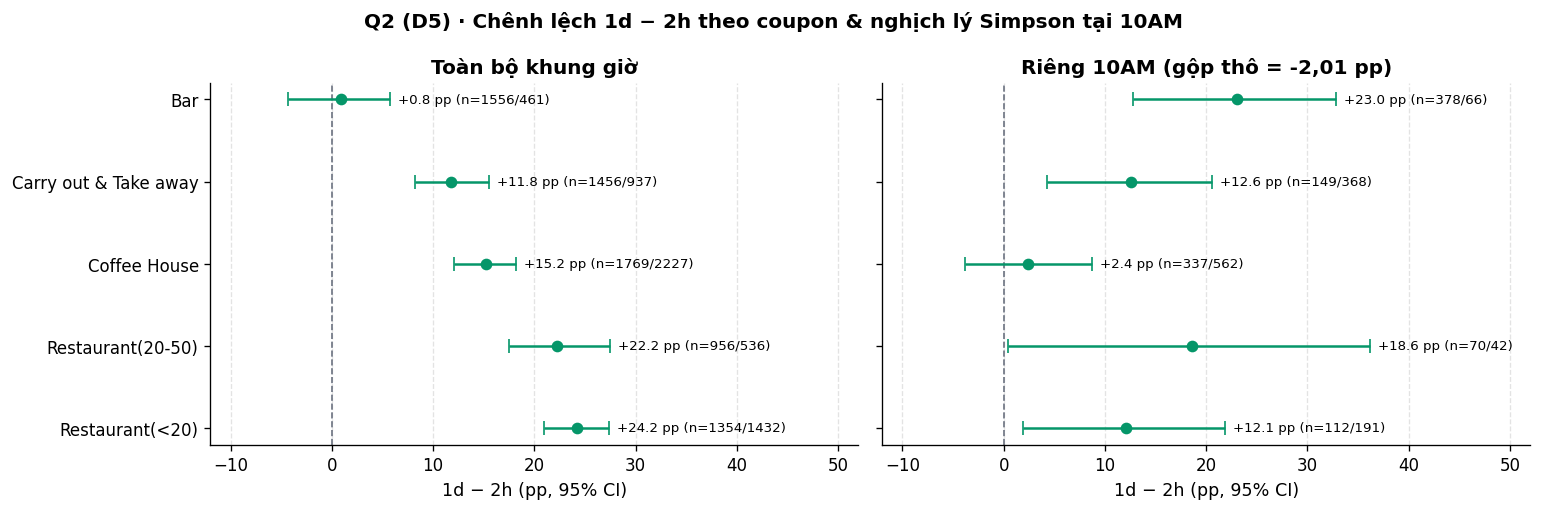

In [5]:
plot_bars_ci(
    rate_table(df, ["time", "expiration"], ci_method="bootstrap"), "time", "expiration",
    TIME_ORDER, EXPIRATION_ORDER,
    "Q2 · Tỷ lệ chấp nhận (%) theo khung giờ & thời hạn (95% CI)", "Khung giờ (time)",
    out_name="q2_fig1_grouped_bar_time_expiration",
    colors=["#F97316", "#2563EB"], figsize=(10.2, 4.5), ylim=(0, 88),
)
plt.show()

coupon_ord_q2 = ["Restaurant(<20)", "Restaurant(20-50)", "Coffee House", "Carry out & Take away", "Bar"]
q2_plot = q2_tc_diff.assign(min_n=q2_tc_diff[["n_a", "n_b"]].min(axis=1))
diff_mat = q2_plot.pivot(index="coupon", columns="time", values="diff_pp").reindex(index=coupon_ord_q2, columns=TIME_ORDER)
min_mat = q2_plot.pivot(index="coupon", columns="time", values="min_n").reindex(index=coupon_ord_q2, columns=TIME_ORDER).fillna(0).astype(int)
plot_heatmap(
    diff_mat, min_mat,
    "Q2 (D4) · Chênh lệch 1d − 2h (điểm %) theo coupon × khung giờ",
    "Khung giờ (time)", "Loại coupon", "1d − 2h (pp)",
    out_name="q2_fig2_heatmap_diff_time_coupon",
    cmap="RdBu", vmin=-45, vmax=45, value_suffix=" pp", signed=True, min_n_warn=40, figsize=(9.8, 4.4),
)
plt.show()

set_style()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
panels = [
    (axes[0], q2_coupon_diff.set_index("coupon").reindex(coupon_ord_q2).reset_index(), "Toàn bộ khung giờ"),
    (axes[1], q2_tc_diff[q2_tc_diff["time"] == "10AM"].set_index("coupon").reindex(coupon_ord_q2).reset_index(), "Riêng 10AM (gộp thô = -2,01 pp)"),
]
for ax, pdf, sub_title in panels:
    ax.axvline(0.0, color="#6B7280", linestyle="--", linewidth=1)
    y_pos = np.arange(len(pdf))
    d = pdf["diff_pp"].to_numpy(float)
    lo = np.maximum(0.0, d - pdf["ci_low_pp"].to_numpy(float))
    hi = np.maximum(0.0, pdf["ci_high_pp"].to_numpy(float) - d)
    for i, (y, val, l, h) in enumerate(zip(y_pos, d, lo, hi)):
        col = "#059669" if val >= 0 else "#DC2626"
        ax.errorbar(val, y, xerr=[[l], [h]], fmt="o", color=col, ecolor=col, capsize=4)
        ax.text(val + h + 0.8, y, f"{val:+.1f} pp (n={int(pdf.loc[i, 'n_a'])}/{int(pdf.loc[i, 'n_b'])})", va="center", fontsize=8)
    ax.set_yticks(y_pos, labels=pdf["coupon"])
    ax.invert_yaxis()
    ax.set(xlim=(-12, 52), xlabel="1d − 2h (pp, 95% CI)", title=sub_title)
    ax.grid(axis="x", linestyle="--", alpha=0.35)

fig.suptitle("Q2 (D5) · Chênh lệch 1d − 2h theo coupon & nghịch lý Simpson tại 10AM", fontweight="bold")
fig.tight_layout()
save_figure(fig, "q2_fig3_coupon_expiration_ci")
plt.show()

**Kết luận Q2 & Hạn chế:**
- Toàn mẫu, `1d` (**62,56%**, `n=7.091`) vượt `2h` (**49,60%**, `n=5.593`) là **+12,96 điểm %**, rõ nhất lúc `10PM` (`+26,13 pp`) và `7AM` (`+20,78 pp`).
- **Nghịch lý Simpson ở `10AM`:** Bảng gộp thô cho `-2,01 pp`, nhưng tách theo từng coupon thì **cả 5/5 loại đều `1d > 2h`** (`+2,41` đến `+23,02 pp`) vì `1d` lúc 10AM chứa tới `36,1%` coupon `Bar` (vs `5,4%` ở `2h`). `Bar` lúc `10PM` đảo chiều nhẹ (`-8,87 pp`).
- **Hạn chế:** `Bar` thiếu hoàn toàn dữ liệu `2h` ở `7AM` và `2PM` (`n=0`); `time` gắn chặt `destination` (`7AM` = 100% `Work`).

---
## Phase 2.2 · Thói quen tiêu dùng & Người đồng hành *(Nguyễn Mạnh Hà — Q3 & Q4)*

### Q3 · Sự phù hợp giữa loại coupon và thói quen ghé thăm (`D3, D4, D5, D6`)
- **Motivation:** Kiểm chứng xem ưu đãi khớp thói quen bản thân có tỷ lệ nhận cao hơn không để phục vụ cá nhân hóa.
- **Phương pháp:** Ánh xạ từng coupon sang cột thói quen (`matched_frequency`, `D3`), so sánh trong từng coupon (`D4`), Wilson + bootstrap 95% CI (`D5`), và kiểm tra độ bền qua 4 biến thể ngưỡng/NaN + loại `74` dòng trùng (`D6`).

In [6]:
q3 = df.copy()
q3["matched_frequency"] = matched_frequency(q3)
q3["frequency_display"] = q3["matched_frequency"].fillna("Unknown")
freq_rates = rate_table(q3, ["coupon", "frequency_display"])

variants = []
thresholds = {"at_least_1": ["1~3", "4~8", "gt8"], "at_least_4": ["4~8", "gt8"]}
for th_name, levels in thresholds.items():
    for method in ["complete_case", "within_coupon_mode"]:
        work = q3[q3["matched_frequency"].notna()].copy() if method == "complete_case" else q3.copy()
        if method == "within_coupon_mode":
            modes = work.groupby("coupon")["matched_frequency"].transform(lambda s: s.mode().iloc[0])
            work["matched_frequency"] = work["matched_frequency"].fillna(modes)
        work["frequent"] = work["matched_frequency"].isin(levels).astype(int)
        res = contrasts(work, ["coupon"], "frequent", 1, 0, n_boot=10000, seed=17104, key=("q3", th_name, method))
        res["threshold"], res["missing_method"] = th_name, method
        variants.append(res)

q3_sens = pd.concat(variants, ignore_index=True)
q3_primary = q3_sens[(q3_sens["threshold"] == "at_least_1") & (q3_sens["missing_method"] == "complete_case")].copy()
display(q3_primary[["coupon", "n_a", "rate_a_pct", "n_b", "rate_b_pct", "diff_pp", "ci_low_pp", "ci_high_pp"]])
display(q3_sens.groupby("coupon").agg(min_pp=("diff_pp", "min"), max_pp=("diff_pp", "max"), pos=("diff_pp", lambda s: int((s > 0).sum()))))
save_table(q3_primary, "q3_primary_contrasts")
save_table(q3_sens, "q3_sensitivity")

q3_dedup_cc = q3.drop_duplicates()
print(row_count_log(len(q3), len(q3_dedup_cc), "Q3 sensitivity drop exact duplicates"))
q3_dedup_cc = q3_dedup_cc[q3_dedup_cc["matched_frequency"].notna()].copy()
q3_dedup_cc["frequent"] = q3_dedup_cc["matched_frequency"].isin(thresholds["at_least_1"]).astype(int)
q3_dedup = contrasts(q3_dedup_cc, ["coupon"], "frequent", 1, 0, n_boot=10000, seed=17104, key="q3_dedup")
print(f"Max |diff_pp| change after dropping duplicates: {np.max(np.abs(q3_dedup['diff_pp'].to_numpy() - q3_primary['diff_pp'].to_numpy())):.2f} pp")

,coupon,n_a,rate_a_pct,n_b,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp
0,Bar,596,68.79,1400,29.21,39.58,35.18,43.97
1,Carry out & Take away,1986,74.37,385,68.57,5.80,0.84,10.91
2,Coffee House,1922,66.02,2002,34.62,31.41,28.42,34.38
3,Restaurant(20-50),506,55.53,964,38.38,17.15,11.84,22.41
4,Restaurant(<20),2245,71.54,514,66.15,5.39,0.93,9.92


,min_pp,max_pp,pos
coupon,,,
Bar,39.45,39.82,4
Carry out & Take away,2.65,5.93,4
Coffee House,22.54,31.41,4
Restaurant(20-50),17.15,21.93,4
Restaurant(<20),3.57,5.60,4


Q3 sensitivity drop exact duplicates: 12,684 -> 12,610 rows (delta -74)
Max |diff_pp| change after dropping duplicates: 0.29 pp


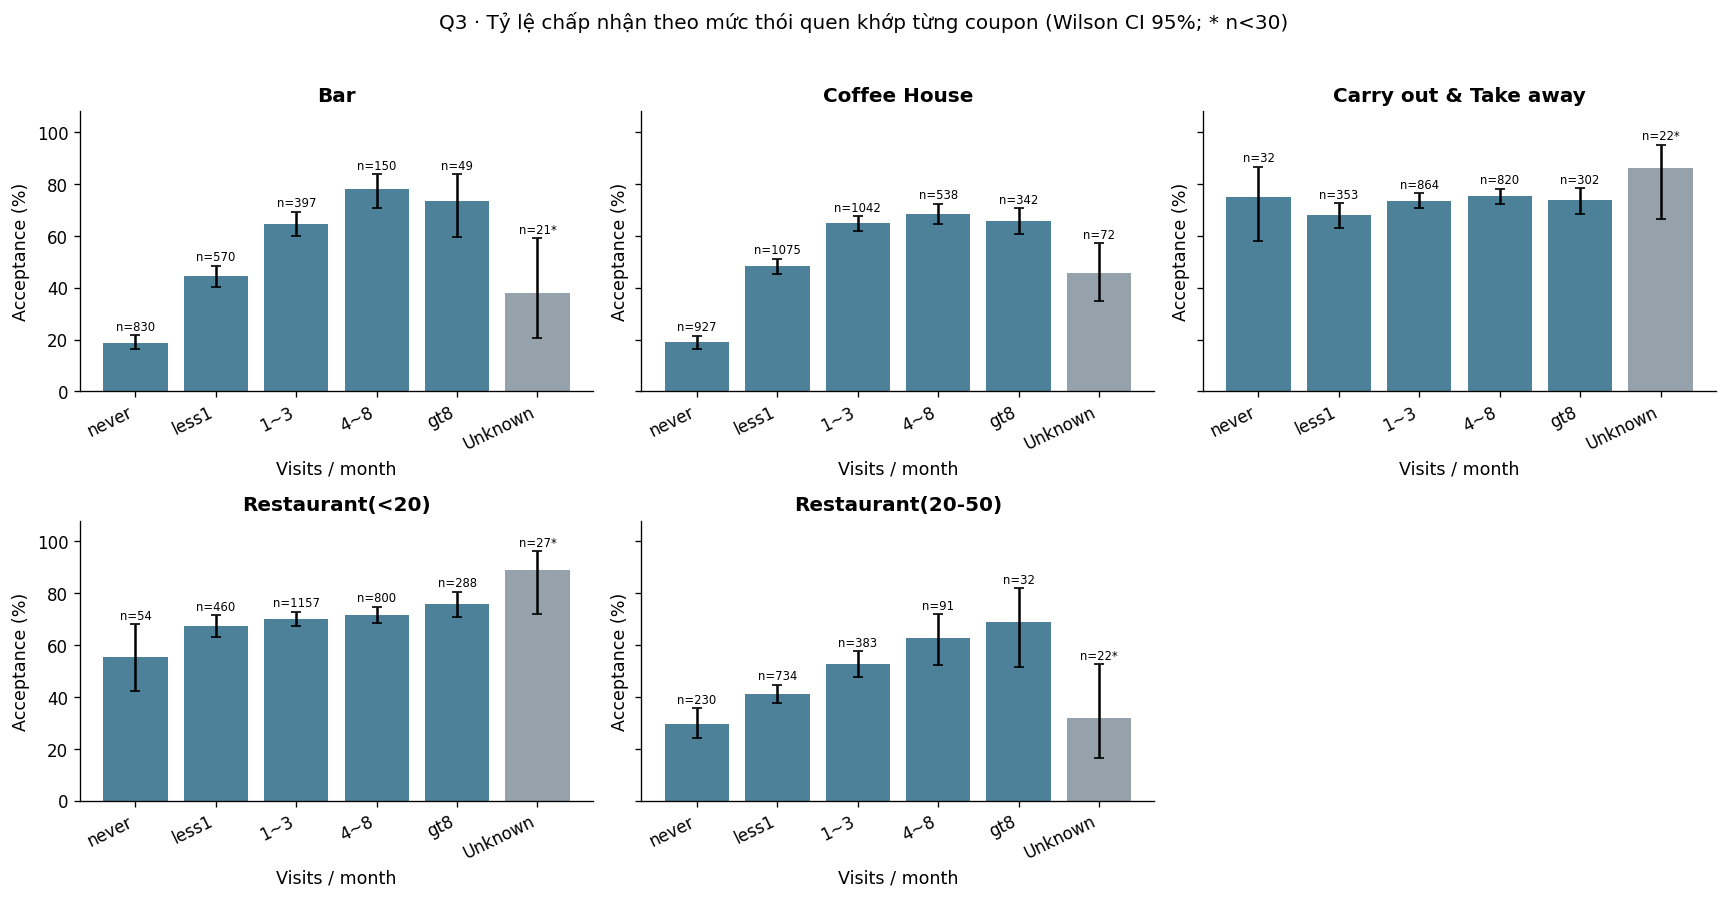

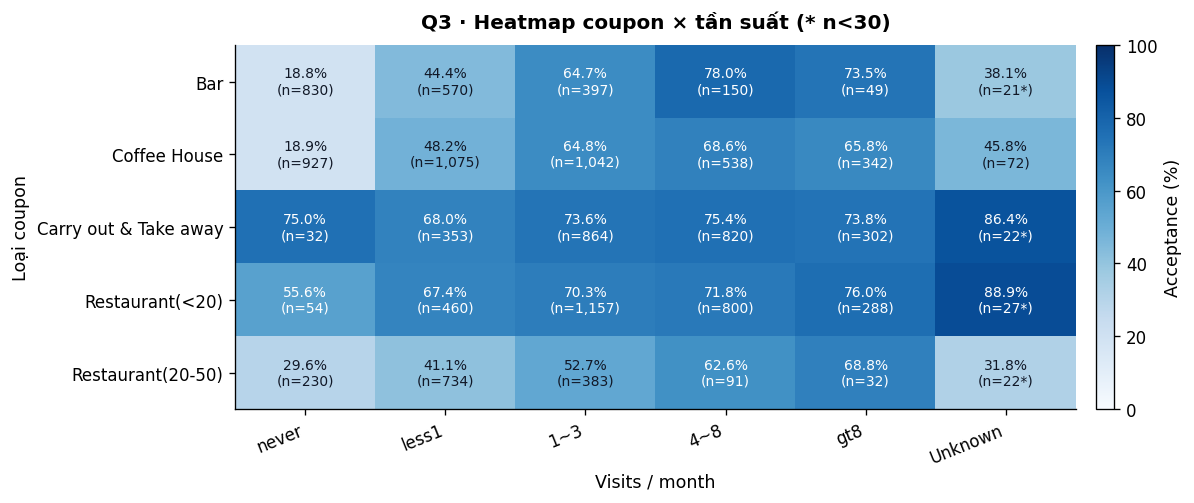

In [7]:
set_style()
freq_ord = FREQUENCIES + ["Unknown"]
fig, axes = plt.subplots(2, 3, figsize=(14.5, 7.6), sharey=True)
for ax, coupon in zip(axes.flat, COUPONS):
    sub = freq_rates[freq_rates["coupon"] == coupon].set_index("frequency_display").reindex(freq_ord)
    for i, lvl in enumerate(freq_ord):
        r = sub.loc[lvl]
        if pd.isna(r["n"]):
            ax.text(i, 3, "n=0", ha="center", fontsize=7); continue
        yerr = np.array([[max(0.0, r["rate_pct"] - r["ci_low_pct"])], [max(0.0, r["ci_high_pct"] - r["rate_pct"])]])
        ax.bar(i, r["rate_pct"], color="#8795a1" if lvl == "Unknown" else "#346e8b", alpha=0.88)
        ax.errorbar(i, r["rate_pct"], yerr=yerr, fmt="none", color="black", capsize=3)
        ax.text(i, min(101, r["ci_high_pct"] + 2), f"n={int(r['n'])}{'*' if r['n'] < MIN_N else ''}", ha="center", fontsize=7)
    ax.set(title=coupon, xlabel="Visits / month", ylabel="Acceptance (%)", ylim=(0, 108))
    ax.set_xticks(range(len(freq_ord)), freq_ord, rotation=26, ha="right")
axes.flat[-1].axis("off")
fig.suptitle("Q3 · Tỷ lệ chấp nhận theo mức thói quen khớp từng coupon (Wilson CI 95%; * n<30)")
fig.tight_layout(rect=(0, 0, 1, 0.96))
save_figure(fig, "q3_frequency_bars")
plt.show()

r_q3 = freq_rates.pivot(index="coupon", columns="frequency_display", values="rate_pct").reindex(index=COUPONS, columns=freq_ord)
c_q3 = freq_rates.pivot(index="coupon", columns="frequency_display", values="n").reindex(index=COUPONS, columns=freq_ord).fillna(0).astype(int)
plot_heatmap(r_q3, c_q3, "Q3 · Heatmap coupon × tần suất (* n<30)", "Visits / month", "Loại coupon", "Acceptance (%)",
             out_name="q3_frequency_heatmap", cmap="Blues", vmin=0, vmax=100, figsize=(10.6, 4.3))
plt.show()

**Kết luận Q3 & Hạn chế:**
- Nhóm thường xuyên (`1~3/4~8/gt8`) chấp nhận cao hơn ở **cả 5/5 coupon**: mạnh nhất ở `Bar` (**68,79%** vs **29,21%**, chênh **+39,58 pp**) và `Coffee House` (**66,02%** vs **34,62%**, **+31,41 pp**), tiếp theo `Restaurant(20-50)` (**+17,15 pp**), `Carry out` (**+5,80 pp**), `Restaurant(<20)` (**+5,39 pp**).
- **Độ bền (D6):** Chiều dương giữ nguyên ở 4/4 biến thể ngưỡng/NaN; bỏ `74` dòng trùng chỉ đổi tối đa `0,29 pp`. Tuy nhiên khi siết ngưỡng `≥4`/tháng, CI của `Carry out` cắt qua 0 (`[-0,72; +6,45]`), và `Bar`/`Coffee House` chững ở `gt8`.
- **Hạn chế:** Tần suất tự khai báo theo khoảng, có `164` dòng thiếu (`1,29%`), chưa tách người trả lời trong bootstrap.

### Q4 · Người đồng hành (`passanger`) & giới hạn common support (`D4, D5`)
- **Motivation:** Xem đi một mình, bạn bè, bạn đời hay trẻ nhỏ liên hệ thế nào sau khi kiểm soát loại coupon và mục đích đi.
- **Phương pháp:** Tính chênh lệch thô vs chuẩn hóa trọng số trên các tầng common support (`n≥30` cả 2 nhóm) theo `coupon × destination` và `has_children` cho `Friend(s) − Alone`, `Partner − Alone`.

In [8]:
coupon_pass = rate_table(df, ["coupon", "passanger"])
joint_pass = rate_table(df, ["coupon", "destination", "passanger"])

crude_rows, std_rows, joint_list = [], [], []
for grp in ["Friend(s)", "Partner"]:
    pair = df[df["passanger"].isin([grp, "Alone"])]
    c_crude = contrasts(pair, [], "passanger", grp, "Alone", n_boot=10000, seed=17104, key=("q4_crude", grp))
    c_joint = contrasts(pair, ["coupon", "destination"], "passanger", grp, "Alone", n_boot=10000, seed=17104, key=("q4_joint", grp))
    c_child = contrasts(pair, ["coupon", "destination", "has_children"], "passanger", grp, "Alone", n_boot=10000, seed=17104, key=("q4_child", grp))
    c_crude["comparison"], c_joint["comparison"] = f"{grp} - Alone", f"{grp} - Alone"
    crude_rows.append(c_crude)
    joint_list.append(c_joint)
    for adj, src in [("coupon_destination", c_joint), ("coupon_destination_children", c_child)]:
        std_rows.append({"comparison": f"{grp} - Alone", "adjustment": adj, **standardized_contrast(src, n_boot=10000, seed=17104, key=("q4_std", adj, grp))})

crude_df = pd.concat(crude_rows, ignore_index=True)
std_df = pd.DataFrame(std_rows)
q4_joint = pd.concat(joint_list, ignore_index=True)
display(crude_df[["comparison", "n_a", "rate_a_pct", "n_b", "rate_b_pct", "diff_pp", "ci_low_pp", "ci_high_pp"]])
display(std_df[["comparison", "adjustment", "n_strata_used", "n_strata_total", "coverage", "diff_pp", "ci_low_pp", "ci_high_pp"]])
display(q4_joint[(q4_joint["status"] == "ok") & (q4_joint["comparison"] == "Friend(s) - Alone")][["coupon", "destination", "n_a", "rate_a_pct", "n_b", "rate_b_pct", "diff_pp", "ci_low_pp", "ci_high_pp"]])

save_table(pd.concat([crude_df.assign(type="crude"), std_df.assign(type="standardized")], ignore_index=True), "q4_crude_vs_standardized")
save_table(q4_joint, "q4_common_support_strata")

,comparison,n_a,rate_a_pct,n_b,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp
0,Friend(s) - Alone,3298,67.34,7305,52.58,14.76,12.81,16.75
1,Partner - Alone,1075,59.53,7305,52.58,6.95,3.83,10.07


,comparison,adjustment,n_strata_used,n_strata_total,coverage,diff_pp,ci_low_pp,ci_high_pp
0,Friend(s) - Alone,coupon_destination,4,15,0.4163,1.33,-1.70,4.51
1,Friend(s) - Alone,coupon_destination_children,7,30,0.3850,2.15,-0.98,5.29
2,Partner - Alone,coupon_destination,8,15,0.5364,3.03,-1.08,7.07
3,Partner - Alone,coupon_destination_children,8,30,0.3394,2.31,-2.34,6.84


,coupon,destination,n_a,rate_a_pct,n_b,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp
1,Bar,No Urgent Place,337,55.79,291,37.80,17.99,10.29,25.66
4,Carry out & Take away,No Urgent Place,739,75.78,75,84.00,-8.22,-16.67,1.00
7,Coffee House,No Urgent Place,1228,59.69,473,58.56,1.13,-4.13,6.43
13,Restaurant(<20),No Urgent Place,826,80.15,445,80.67,-0.53,-5.09,4.07


WindowsPath('C:/Users/MY MSI/Desktop/Môn học/Chuyên ngành/Data Science Programming/Project/reports/tables/q4_common_support_strata.csv')

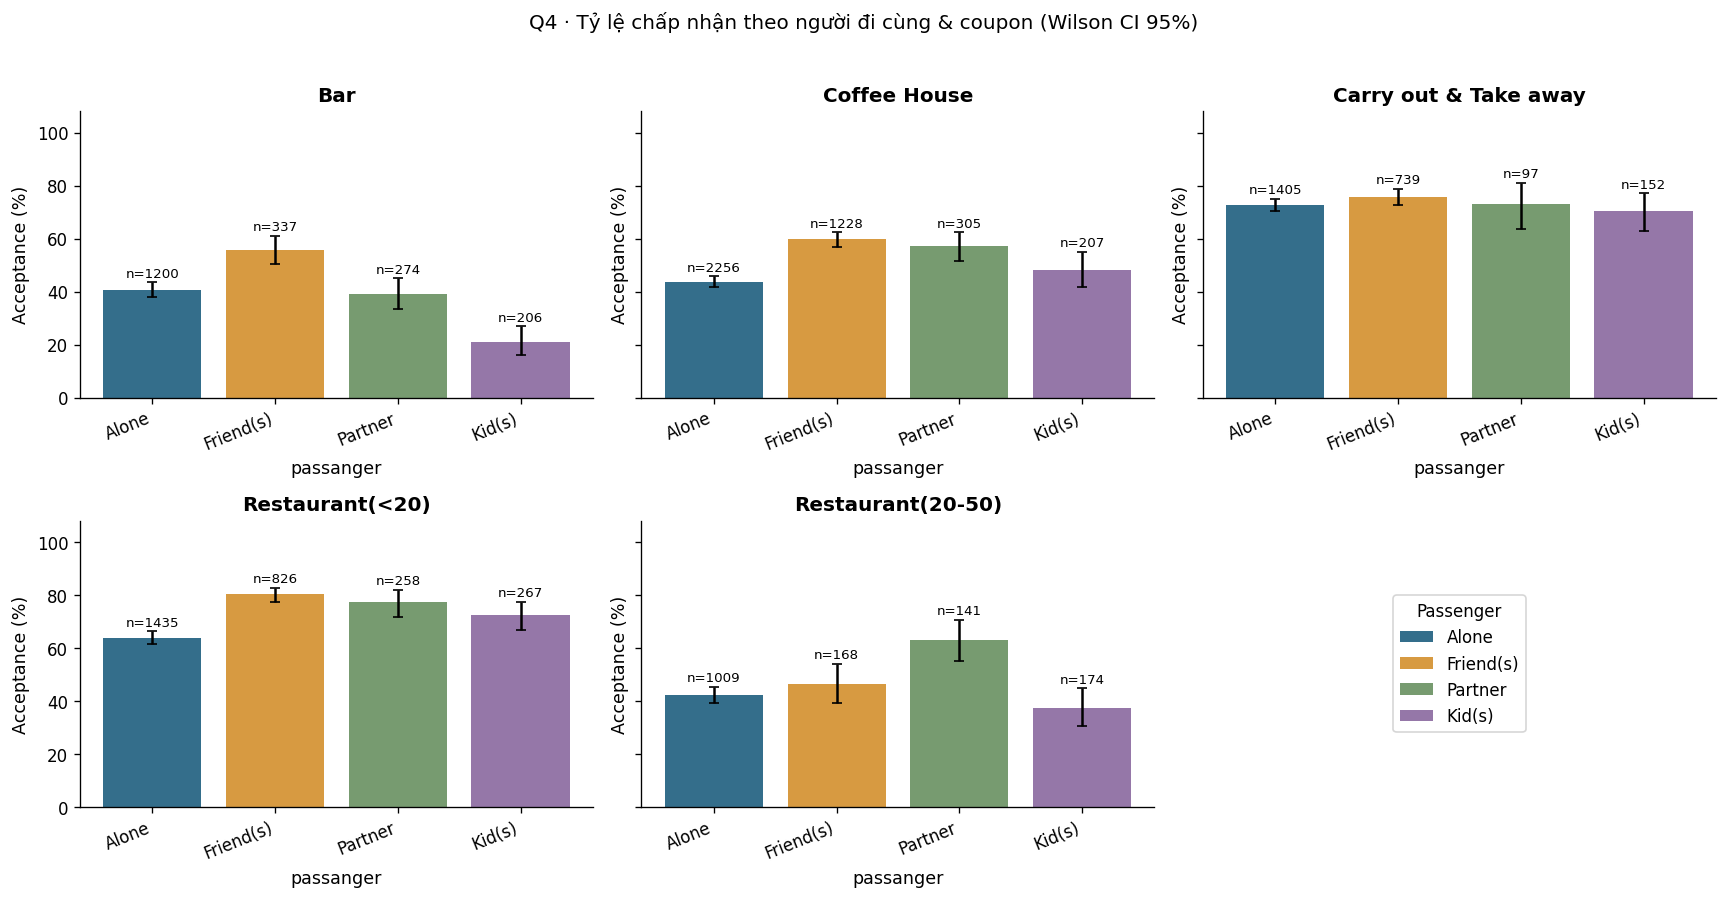

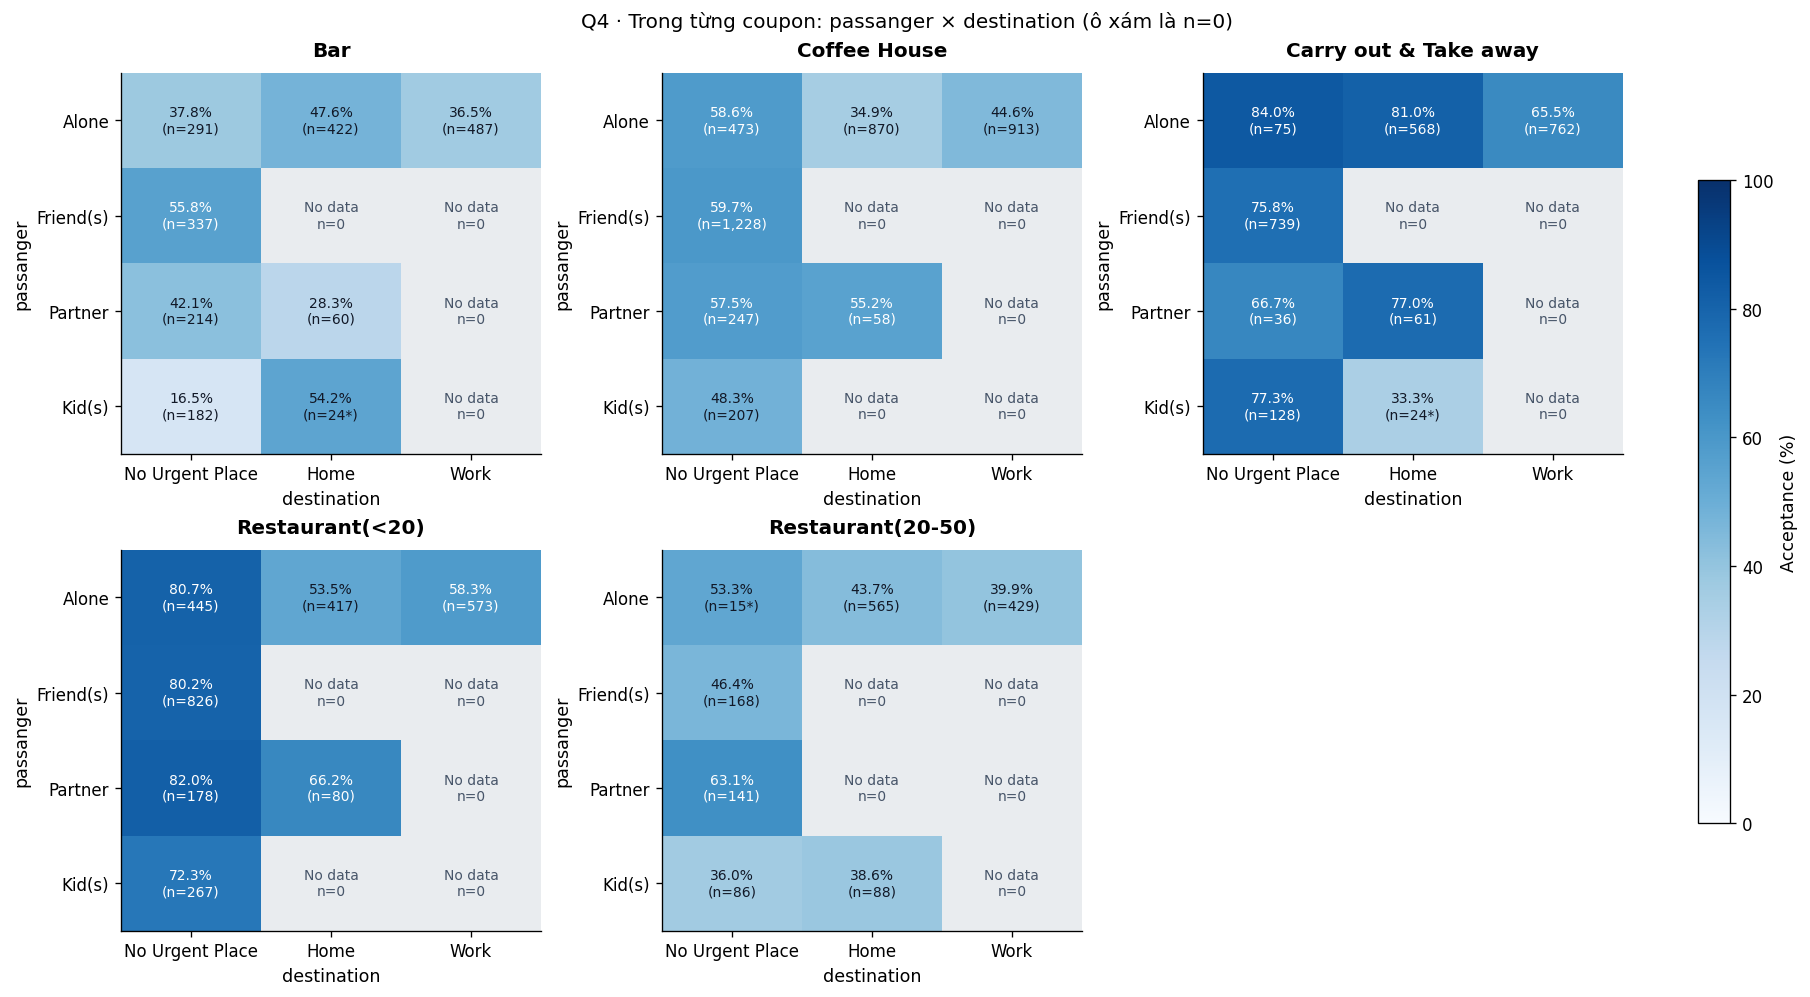

In [9]:
set_style()
fig, axes = plt.subplots(2, 3, figsize=(14.5, 7.6), sharey=True)
colors = ["#346e8b", "#d79a41", "#779b70", "#9577a8"]
for ax, coupon in zip(axes.flat, COUPONS):
    part = coupon_pass[coupon_pass["coupon"] == coupon].set_index("passanger").reindex(PASSENGERS)
    for i, p in enumerate(PASSENGERS):
        r = part.loc[p]
        if pd.isna(r["n"]): continue
        yerr = np.array([[max(0.0, r["rate_pct"] - r["ci_low_pct"])], [max(0.0, r["ci_high_pct"] - r["rate_pct"])]])
        ax.bar(i, r["rate_pct"], color=colors[i], label=p)
        ax.errorbar(i, r["rate_pct"], yerr=yerr, fmt="none", color="black", capsize=3)
        ax.text(i, min(101, r["ci_high_pct"] + 2), f"n={int(r['n'])}", ha="center", fontsize=8)
    ax.set(title=coupon, xlabel="passanger", ylabel="Acceptance (%)", ylim=(0, 108))
    ax.set_xticks(range(4), PASSENGERS, rotation=22, ha="right")
axes.flat[-1].axis("off")
h, l = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(h, l, loc="center", title="Passenger")
fig.suptitle("Q4 · Tỷ lệ chấp nhận theo người đi cùng & coupon (Wilson CI 95%)")
fig.tight_layout(rect=(0, 0, 1, 0.96))
save_figure(fig, "q4_passanger_bars")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15.0, 8.2), constrained_layout=True)
for ax, coupon in zip(axes.flat, COUPONS):
    sub = joint_pass[joint_pass["coupon"] == coupon]
    r_mat = sub.pivot(index="passanger", columns="destination", values="rate_pct").reindex(index=PASSENGERS, columns=DESTINATIONS)
    c_mat = sub.pivot(index="passanger", columns="destination", values="n").reindex(index=PASSENGERS, columns=DESTINATIONS).fillna(0).astype(int)
    _, _, img = plot_heatmap(r_mat, c_mat, coupon, "destination", "passanger", cmap="Blues", vmin=0, vmax=100, ax=ax)
axes.flat[-1].axis("off")
fig.colorbar(img, ax=list(axes.flat), shrink=0.75, label="Acceptance (%)")
fig.suptitle("Q4 · Trong từng coupon: passanger × destination (ô xám là n=0)")
save_figure(fig, "q4_destination_heatmaps")
plt.show()

**Kết luận Q4 & Hạn chế:**
- Gộp thô, `Friend(s)` cao hơn `Alone` **+14,76 pp**, `Partner` hơn `Alone` **+6,95 pp**. Sau chuẩn hóa theo `coupon × destination`, chênh lệch thu hẹp còn **+1,33 pp** (CI `[-1,70; +4,51]`, chỉ `4/15` tầng hay `41,6%` mẫu cặp đủ `n≥30`) và **+3,03 pp** (CI `[-1,08; +7,07]`).
- Nguyên nhân: `Friend(s)` có `3.298` dòng ở `No Urgent Place` nhưng **`0` dòng** ở `Home`/`Work`. Trong riêng `Bar` tại `No Urgent Place`, `Friend(s)` vẫn vượt `Alone` **+17,99 pp**, và `6/12` tầng đủ mẫu đổi dấu so với mức chưa phân tầng.
- **Hạn chế:** Thiếu common support ở `Home`/`Work` cho `Friend(s)`; `has_children` là có con chứ không khẳng định trẻ đang ngồi trên xe.

---
## Phase 2.3 · Phân khúc tuổi & thu nhập theo người trả lời *(Hoàng Công Lý — Q5)*

### Q5 · Tuổi & thu nhập sau khi kiểm soát loại coupon và thói quen (`D4, D5, D6`)
- **Câu hỏi:** Mối liên hệ giữa nhóm tuổi, khoảng thu nhập và tỷ lệ chấp nhận coupon có còn quan sát thấy khi so sánh **trong cùng loại coupon** và **cùng mức thói quen** đến địa điểm tương ứng không?
- **Motivation:** Đội marketing hay phân khúc theo tuổi/thu nhập. Nếu khác biệt thật ra đến từ thói quen ghé quán (người trẻ đi bar nhiều hơn), nhắm theo tuổi sẽ kém hiệu quả hơn nhắm theo thói quen.
- **Dữ liệu & gộp nhóm:** `age` (có `below21`, `50plus`) và `income` (khoảng tiền) giữ dạng phân loại có thứ tự, không ép sang số. Gộp thành 4 nhóm tuổi (`<26`, `26–35`, `36–50`, `50+`) và 3 nhóm thu nhập (ranh giới `37,5k` và `75k`) để mỗi nhóm đủ nhiều người khi chia tiếp theo coupon × thói quen (bảng số người bên dưới).
- **Phương pháp:** Dựng `respondent_id` từ các cột hồ sơ trùng nhau; loại dòng thiếu `matched_frequency` (không đổi thành `never`); chuẩn hóa trực tiếp `coupon × thói quen` (`D4`); cluster-bootstrap 95% CI theo người (`D5`); kiểm tra độ bền cách gộp tuổi/thu nhập, ngưỡng `≥4`/tháng và đơn vị bootstrap (`D6`).

In [10]:
HABIT_COLS = list(COUPON_FREQUENCY.values())
PROFILE_COLS = ["gender", "age", "maritalStatus", "has_children", "education", "occupation", "income", "car"] + HABIT_COLS
AGE_ORDER = ["below21", "21", "26", "31", "36", "41", "46", "50plus"]
INCOME_ORDER = ["Less than $12500", "$12500 - $24999", "$25000 - $37499", "$37500 - $49999",
                "$50000 - $62499", "$62500 - $74999", "$75000 - $87499", "$87500 - $99999", "$100000 or More"]
INCOME_SHORT = ["<12.5k", "12.5–25k", "25–37.5k", "37.5–50k", "50–62.5k", "62.5–75k", "75–87.5k", "87.5–100k", "≥100k"]
AGE_GROUPS = ["<26", "26–35", "36–50", "50+"]
INCOME_GROUPS = ["Thấp (<37.5k)", "Trung bình (37.5k–<75k)", "Cao (≥75k)"]

q5 = df[["age", "income", "coupon"] + HABIT_COLS + ["Y"]].copy()
q5["respondent_id"] = build_respondent_id(df, PROFILE_COLS)
q5["age"] = pd.Categorical(q5["age"], categories=AGE_ORDER, ordered=True)
q5["income"] = pd.Categorical(q5["income"], categories=INCOME_ORDER, ordered=True)
q5["age_group"] = pd.Categorical(q5["age"].astype(str).map({"below21": "<26", "21": "<26", "26": "26–35", "31": "26–35", "36": "36–50", "41": "36–50", "46": "36–50", "50plus": "50+"}), categories=AGE_GROUPS, ordered=True)
q5["income_group"] = pd.Categorical(q5["income"].astype(str).map(dict(zip(INCOME_ORDER, [INCOME_GROUPS[0]]*3 + [INCOME_GROUPS[1]]*3 + [INCOME_GROUPS[2]]*3))), categories=INCOME_GROUPS, ordered=True)
q5["matched_frequency"] = matched_frequency(q5)
q5["frequent_user"] = pd.Categorical(q5["matched_frequency"].map({"never": "Ít (<1)", "less1": "Ít (<1)", "1~3": "Thường (≥1)", "4~8": "Thường (≥1)", "gt8": "Thường (≥1)"}), categories=["Ít (<1)", "Thường (≥1)"], ordered=True)
q5["frequent_alt"] = pd.Categorical(q5["matched_frequency"].map({"never": "Ít (<4)", "less1": "Ít (<4)", "1~3": "Ít (<4)", "4~8": "Thường (≥4)", "gt8": "Thường (≥4)"}), categories=["Ít (<4)", "Thường (≥4)"], ordered=True)

q5_cc = q5.dropna(subset=["matched_frequency"]).copy()
print(row_count_log(len(q5), len(q5_cc), "Q5 complete-case matched_frequency"))
print(f"Inferred respondents: {q5['respondent_id'].nunique()} -> {q5_cc['respondent_id'].nunique()} after drop")

rows = []
for name, col, ga, gb in [("Tuổi <26 − 50+", "age_group", "<26", "50+"), ("Thu nhập Thấp − Cao", "income_group", INCOME_GROUPS[0], INCOME_GROUPS[2])]:
    for adj, strata in [("Thô", ()), ("Chuẩn hoá coupon", ("coupon",)), ("Chuẩn hoá coupon × thói quen", ("coupon", "frequent_user"))]:
        rows.append({"so_sanh": name, "pham_vi": "Tất cả coupon", "dieu_chinh": adj, **cluster_diff_ci(q5_cc, col, ga, gb, strata)})
    for c in COUPONS:
        sub = q5_cc[q5_cc["coupon"] == c]
        for adj, strata in [("Thô", ()), ("Chuẩn hoá thói quen", ("frequent_user",))]:
            rows.append({"so_sanh": name, "pham_vi": c, "dieu_chinh": adj, **cluster_diff_ci(sub, col, ga, gb, strata)})
q5_contrasts = pd.DataFrame(rows)
display(q5_contrasts[q5_contrasts["pham_vi"] == "Tất cả coupon"])
save_table(q5_contrasts, "q5_contrasts")

cross_ctrl = pd.DataFrame([
    {"phuong_an": "Tuổi <26 − 50+ (giữ thu nhập)", **cluster_diff_ci(q5_cc, "age_group", "<26", "50+", ("coupon", "income_group"))},
    {"phuong_an": "Thu nhập Thấp − Cao (giữ tuổi)", **cluster_diff_ci(q5_cc, "income_group", INCOME_GROUPS[0], INCOME_GROUPS[2], ("coupon", "age_group"))},
])
q5_cc["age_bin"] = pd.Categorical(q5_cc["age"].astype(str).map(dict(zip(AGE_ORDER, ["<36"]*4 + ["36+"]*4))), categories=["<36", "36+"], ordered=True)
q5_cc["inc_bin"] = pd.Categorical(q5_cc["income"].astype(str).map(dict(zip(INCOME_ORDER, ["<50k"]*4 + ["≥50k"]*5))), categories=["<50k", "≥50k"], ordered=True)
sens_df = pd.concat([cross_ctrl, pd.DataFrame([
    {"phuong_an": "Tuổi <26−50+ (ngưỡng ≥4/tháng)", **cluster_diff_ci(q5_cc, "age_group", "<26", "50+", ("coupon", "frequent_alt"))},
    {"phuong_an": "Tuổi <36−36+ (chia đôi, chuẩn hoá)", **cluster_diff_ci(q5_cc, "age_bin", "<36", "36+", ("coupon", "frequent_user"))},
    {"phuong_an": "Tuổi <26−50+ (bootstrap theo dòng)", **cluster_diff_ci(q5_cc, "age_group", "<26", "50+", ("coupon", "frequent_user"), unit="row")},
    {"phuong_an": "Thu nhập <50k−≥50k (chia đôi, chuẩn hoá)", **cluster_diff_ci(q5_cc, "inc_bin", "<50k", "≥50k", ("coupon", "frequent_user"))},
])], ignore_index=True)
display(sens_df)
save_table(sens_df, "q5_sensitivity")

Q5 complete-case matched_frequency: 12,684 -> 12,520 rows (delta -164)
Inferred respondents: 567 -> 560 after drop


,so_sanh,pham_vi,dieu_chinh,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,empty_strata_draws
0,Tuổi <26 − 50+,Tất cả coupon,Thô,60.4,50.7,9.7,4.5,15.0,0
1,Tuổi <26 − 50+,Tất cả coupon,Chuẩn hoá coupon,60.4,50.6,9.8,4.6,15.1,0
2,Tuổi <26 − 50+,Tất cả coupon,Chuẩn hoá coupon × thói quen,59.7,52.2,7.5,2.8,12.4,0
13,Thu nhập Thấp − Cao,Tất cả coupon,Thô,58.8,54.2,4.6,0.4,8.7,0
14,Thu nhập Thấp − Cao,Tất cả coupon,Chuẩn hoá coupon,58.6,54.2,4.4,0.2,8.6,0
15,Thu nhập Thấp − Cao,Tất cả coupon,Chuẩn hoá coupon × thói quen,58.6,54.2,4.4,0.4,8.4,0


,phuong_an,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,empty_strata_draws
0,Tuổi <26 − 50+ (giữ thu nhập),61.1,50.7,10.4,5.1,15.9,0
1,Thu nhập Thấp − Cao (giữ tuổi),58.7,54.9,3.8,-0.6,7.8,0
2,Tuổi <26−50+ (ngưỡng ≥4/tháng),60.1,50.3,9.8,4.8,14.9,45
3,"Tuổi <36−36+ (chia đôi, chuẩn hoá)",58.1,54.9,3.2,-0.1,6.5,0
4,Tuổi <26−50+ (bootstrap theo dòng),59.7,52.2,7.5,4.8,10.2,0
5,"Thu nhập <50k−≥50k (chia đôi, chuẩn hoá)",58.2,55.3,2.9,-0.3,6.0,0


PosixPath('/Users/hoangcongly/Documents/Learning/LT_KHDL/labcuoiky/repo/reports/tables/q5_sensitivity.csv')

In [11]:
# Kiểm tra respondent_id: phần lớn người có đúng 22 dòng (khớp thiết kế khảo sát)
rows_per_person = q5["respondent_id"].value_counts()
print(f"Số người: {len(rows_per_person)} | có đúng 22 dòng: {(rows_per_person == 22).mean():.1%}")

# Bảng nhóm có n: số dòng, số người, tỷ lệ chấp nhận và CI 95% theo người (toàn mẫu, chưa kiểm soát)
def group_table(data, col):
    ci = cluster_rates_ci(data, col)
    ci["n_dong"] = data.groupby(col, observed=False).size()
    ci["n_nguoi"] = data.groupby(col, observed=False)["respondent_id"].nunique()
    return ci[["n_dong", "n_nguoi", "rate_pct", "ci_low_pct", "ci_high_pct"]]

q5_age_table = group_table(q5, "age_group")
q5_income_table = group_table(q5, "income")
q5_income_table.index = INCOME_SHORT
display(q5_age_table)
display(q5_income_table)
save_table(q5_age_table.reset_index(names="age_group"), "q5_age_groups")
save_table(q5_income_table.reset_index(names="income"), "q5_income_levels")

# Ô nhỏ: đếm số người trong từng ô coupon × thói quen × nhóm tuổi (5 × 2 × 4 = 40 ô)
cell_people = q5_cc.groupby(["coupon", "frequent_user", "age_group"], observed=False)["respondent_id"].nunique()
print(f"Ô coupon × thói quen × tuổi có < 30 người: {(cell_people < 30).sum()}/{len(cell_people)} (nhỏ nhất: {cell_people.min()} người)")

# Chênh lệch trong từng loại coupon (D4 + D5): thô và sau khi chuẩn hoá thói quen
per_coupon = q5_contrasts[q5_contrasts["pham_vi"] != "Tất cả coupon"]
display(per_coupon[["so_sanh", "pham_vi", "dieu_chinh", "rate_a_pct", "rate_b_pct", "diff_pp", "ci_low_pp", "ci_high_pp"]])

Số người: 567 | có đúng 22 dòng: 86.2%


,n_dong,n_nguoi,rate_pct,ci_low_pct,ci_high_pct
<26,3200,143,60.44,57.47,63.32
26–35,4598,204,57.39,54.55,60.19
36–50,3098,136,55.75,52.36,59.13
50+,1788,84,50.89,46.52,54.87


,n_dong,n_nguoi,rate_pct,ci_low_pct,ci_high_pct
<12.5k,1042,46,59.31,54.46,64.23
12.5–25k,1831,82,57.45,53.12,61.99
25–37.5k,2013,93,59.31,55.19,63.64
37.5–50k,1805,81,56.40,52.18,60.80
50–62.5k,1659,75,59.55,55.68,63.56
62.5–75k,846,39,52.72,45.01,60.25
75–87.5k,857,38,48.31,41.85,54.66
87.5–100k,895,40,53.18,45.34,60.02
≥100k,1736,73,57.83,53.56,62.11


Ô coupon × thói quen × tuổi có < 30 người: 9/40 (nhỏ nhất: 10 người)


,so_sanh,pham_vi,dieu_chinh,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp
3,Tuổi <26 − 50+,Bar,Thô,49.1,29.5,19.6,8.0,30.1
4,Tuổi <26 − 50+,Bar,Chuẩn hoá thói quen,47.7,32.5,15.2,4.8,24.7
5,Tuổi <26 − 50+,Coffee House,Thô,54.9,41.7,13.2,3.6,22.6
6,Tuổi <26 − 50+,Coffee House,Chuẩn hoá thói quen,52.9,44.1,8.8,1.5,16.8
7,Tuổi <26 − 50+,Carry out & Take away,Thô,73.5,77.1,-3.7,-11.2,3.9
8,Tuổi <26 − 50+,Carry out & Take away,Chuẩn hoá thói quen,73.5,78.4,-5.0,-12.5,2.6
9,Tuổi <26 − 50+,Restaurant(<20),Thô,73.9,63.6,10.3,2.3,17.9
10,Tuổi <26 − 50+,Restaurant(<20),Chuẩn hoá thói quen,74.2,63.7,10.5,2.3,18.2
11,Tuổi <26 − 50+,Restaurant(20-50),Thô,44.2,35.6,8.6,-2.1,18.8
12,Tuổi <26 − 50+,Restaurant(20-50),Chuẩn hoá thói quen,44.7,36.7,8.0,-2.4,18.0


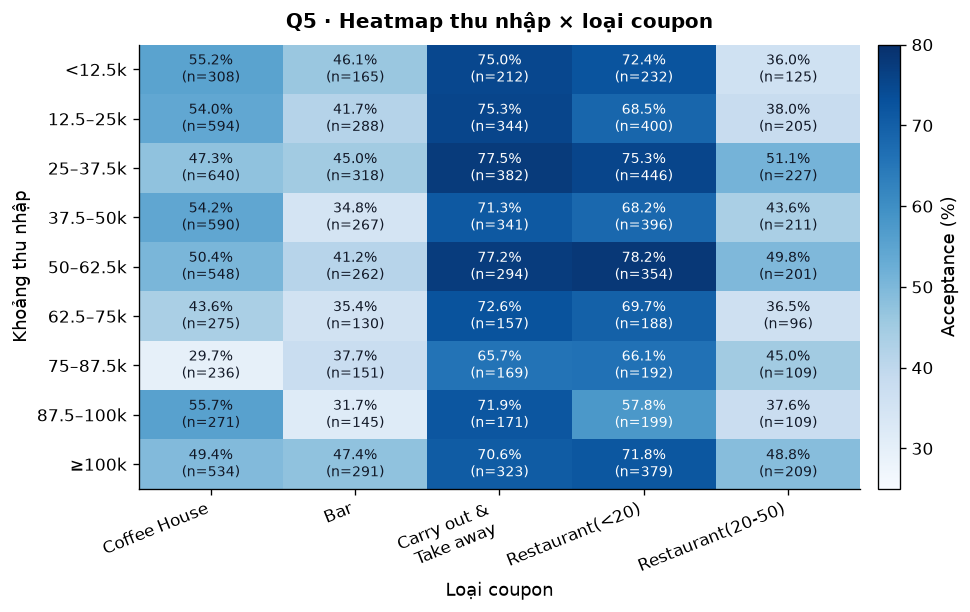

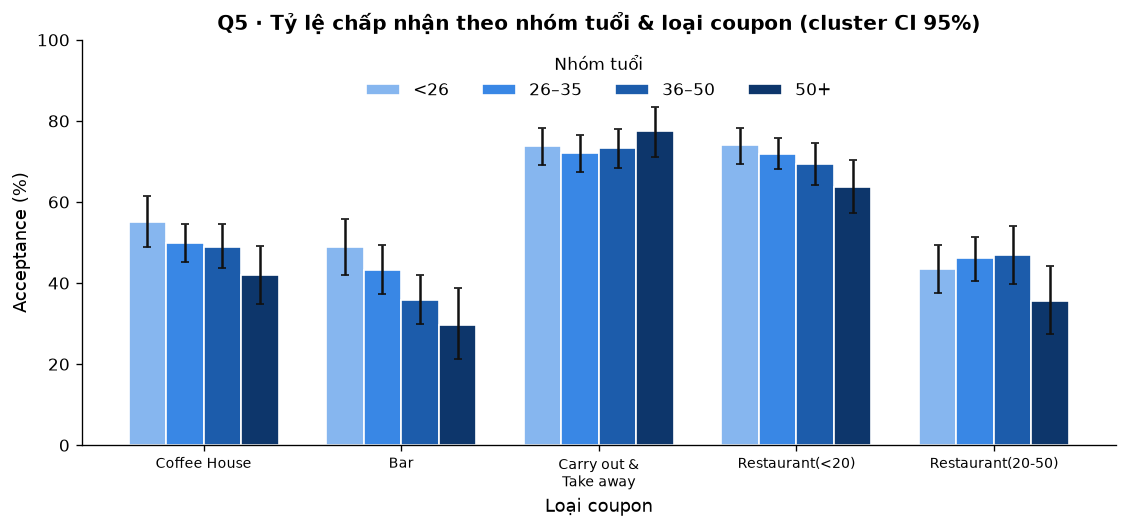

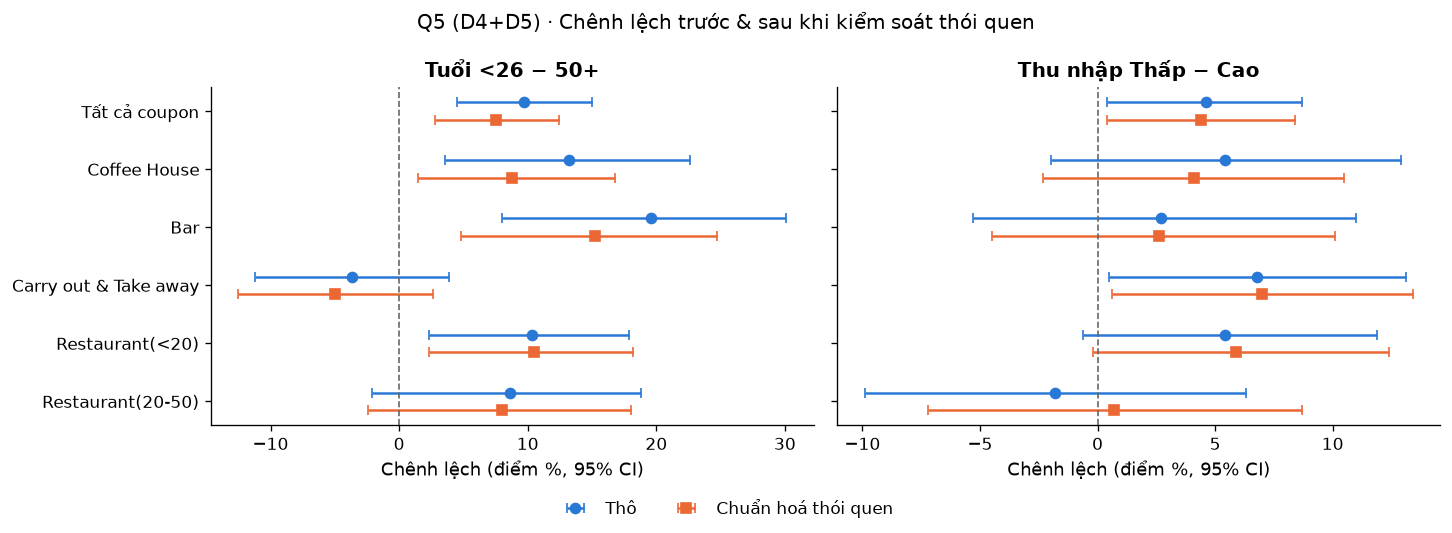

In [12]:
set_style()
coupon_ord_q5 = ["Coffee House", "Bar", "Carry out & Take away", "Restaurant(<20)", "Restaurant(20-50)"]
rate_ic = q5.pivot_table("Y", "income", "coupon", "mean", observed=True)[coupon_ord_q5].mul(100)
n_ic = q5.pivot_table("Y", "income", "coupon", "count", observed=True)[coupon_ord_q5]
rate_ic.index = INCOME_SHORT
rate_ic.columns = [c.replace(" & ", " &\n") for c in coupon_ord_q5]
n_ic.index, n_ic.columns = rate_ic.index, rate_ic.columns
plot_heatmap(rate_ic, n_ic, "Q5 · Heatmap thu nhập × loại coupon", "Loại coupon", "Khoảng thu nhập",
             out_name="q5_fig1_income_coupon_heatmap", cmap="Blues", vmin=25, vmax=80, figsize=(8.6, 5.2))
plt.show()

age_ci = {c: cluster_rates_ci(q5[q5["coupon"] == c], "age_group") for c in coupon_ord_q5}
x, bw = np.arange(5), 0.19
age_cols = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
fig, ax = plt.subplots(figsize=(9.5, 4.5))
for k, ag in enumerate(AGE_GROUPS):
    r = np.array([age_ci[c].loc[ag, "rate_pct"] for c in coupon_ord_q5])
    lo = np.array([age_ci[c].loc[ag, "ci_low_pct"] for c in coupon_ord_q5])
    hi = np.array([age_ci[c].loc[ag, "ci_high_pct"] for c in coupon_ord_q5])
    pos = x + (k - 1.5) * bw
    ax.bar(pos, r, width=bw, color=age_cols[k], edgecolor="white", label=ag)
    ax.errorbar(pos, r, yerr=[r - lo, hi - r], fmt="none", ecolor="#111", capsize=2.5)
ax.set_xticks(x, [c.replace(" & ", " &\n") for c in coupon_ord_q5], fontsize=8.5)
ax.set(ylim=(0, 100), title="Q5 · Tỷ lệ chấp nhận theo nhóm tuổi & loại coupon (cluster CI 95%)", xlabel="Loại coupon", ylabel="Acceptance (%)")
ax.legend(title="Nhóm tuổi", ncol=4, loc="upper center", frameon=False)
fig.tight_layout()
save_figure(fig, "q5_fig2_age_group_by_coupon")
plt.show()

scopes = ["Tất cả coupon"] + coupon_ord_q5
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4), sharey=True)
for ax, cname in zip(axes, ["Tuổi <26 − 50+", "Thu nhập Thấp − Cao"]):
    part = q5_contrasts[q5_contrasts["so_sanh"] == cname]
    for lbl, col, mk, off in [("Thô", "#2a78d6", "o", -0.15), ("Chuẩn hoá thói quen", "#eb6834", "s", 0.15)]:
        sel = part[part["dieu_chinh"] == lbl] if lbl == "Thô" else part[part["dieu_chinh"].isin(["Chuẩn hoá coupon × thói quen", "Chuẩn hoá thói quen"])]
        sel = sel.set_index("pham_vi").loc[scopes]
        y = np.arange(len(scopes)) + off
        d = sel["diff_pp"].to_numpy()
        ax.errorbar(d, y, xerr=[d - sel["ci_low_pp"].to_numpy(), sel["ci_high_pp"].to_numpy() - d], fmt=mk, color=col, capsize=3, label=lbl)
    ax.axvline(0, color="#666", linestyle="--", linewidth=1)
    ax.set(title=cname, xlabel="Chênh lệch (điểm %, 95% CI)")
axes[0].set_yticks(range(len(scopes)), scopes)
axes[0].invert_yaxis()
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Q5 (D4+D5) · Chênh lệch trước & sau khi kiểm soát thói quen")
fig.tight_layout(rect=(0, 0.06, 1, 1))
save_figure(fig, "q5_fig3_contrasts_raw_vs_adjusted")
plt.show()

**Kết luận Q5** *(CI 95% bootstrap theo người; so sánh có kiểm soát thói quen dùng `12.520` dòng)*

1. **Trong cùng loại coupon, nhóm nào nhận nhiều/ít?** Tính thô, tỷ lệ giảm dần theo tuổi: `<26` **60,4%** (`3.200` dòng, `143` người, CI `[57,5; 63,3]`) → `50+` **50,9%** (`1.788` dòng, `84` người, CI `[46,5; 54,9]`). Trong từng coupon, chênh `<26 − 50+` lớn nhất ở `Bar` (**+19,6 pp**, CI `[8,0; 30,1]`), `Coffee House` (`+13,2 pp`) và `Restaurant(<20)` (`+10,3 pp`); `Restaurant(20-50)` chưa rõ (`+8,6 pp`, CI chứa 0) và `Carry out` hơi ngược chiều (`−3,7 pp`, CI `[−11,2; 3,9]`). Thu nhập không giảm theo đường thẳng: thấp nhất ở `75–87,5k` (**48,3%**, `38` người) nhưng `≥100k` lại **57,8%** (`73` người).
2. **Sau khi kiểm soát thói quen:** chênh lệch tuổi giảm từ `+9,7` còn **+7,5 pp** (CI `[2,8; 12,4]`), tức khoảng 1/4 khác biệt đi cùng thói quen; phần còn lại vẫn rõ ở `Bar` (`+15,2 pp`), `Coffee House` (`+8,8 pp`), `Restaurant(<20)` (`+10,5 pp`). Thu nhập `Thấp − Cao` chỉ **+4,4 pp** (CI `[0,4; 8,4]`, sát 0) và khi giữ cố định nhóm tuổi còn `+3,8 pp` (CI `[−0,6; 7,8]`), không còn phân biệt được với 0.
3. **Ô nhỏ:** `9/40` ô `coupon × thói quen × tuổi` có `< 30` người (nhỏ nhất `10` người), nên CI trong từng coupon rộng (ví dụ `Bar` rộng ~22 pp). Ba khoảng thu nhập `62,5k–100k` chỉ có `38–40` người, CI rộng ~13–15 pp.
4. **Đổi cách gộp (D6):** Chênh lệch tuổi luôn dương ở mọi phương án, nhưng chia đôi `<36 − 36+` chỉ còn `+3,2 pp` (CI `[−0,1; 6,5]`): khác biệt nằm chủ yếu ở hai đầu tuổi. Ngưỡng thói quen `≥4`/tháng cho kết quả tương tự (`+9,8 pp`) nhưng `45/2000` lần bootstrap có tầng rỗng vì ít người đạt ngưỡng. Thu nhập chia đôi `<50k − ≥50k` cũng chứa 0 (`+2,9 pp`) nên kết luận về thu nhập ổn định. Bootstrap theo dòng cho CI hẹp hơn ~1,8 lần (rộng `5,4` so với `9,6` pp): bỏ qua việc một người trả lời 22 kịch bản sẽ làm kết luận tự tin quá mức.

- **Điểm bất ngờ:** Giả thuyết "thu nhập càng cao càng ít cần coupon" không đúng trong khảo sát: nhóm `≥100k` nhận gần bằng nhóm thấp nhất. `Carry out` là coupon duy nhất mà người `50+` nhận nhiều hơn người `<26`.
- **Ứng dụng có điều kiện:** Khi phân khúc, loại coupon và thói quen hữu ích hơn thu nhập; tuổi chỉ đáng dùng thêm cho `Bar`/`Coffee House`. Chỉ áp dụng trong phạm vi khảo sát ý định này.
- **Hạn chế:** Dữ liệu MTurk đo ý định giả định; `respondent_id` suy ra từ hồ sơ trùng; thói quen chỉ được kiểm soát ở 2 mức nên vẫn có thể còn biến nhiễu khác; đây là mối liên hệ quan sát, không phải nhân quả.

---
## Phase 2.4 · Tổng hợp Q1–Q6, Hạn chế, Hướng phát triển & Reflections

| Câu | Owner | Kết luận định lượng cốt lõi |
| --- | --- | --- |
| **Q1** | Dương | Gần (`5–<15 min`: **61,42%**) > xa (`≥25 min`: **42,89%**, **+18,53 pp**); `Restaurant(<20)` sụt **42,74 pp** còn `Carry out` giữ phẳng (**73,21%**); đi cùng hướng trong `Home` tăng **+17,40 pp**. |
| **Q2** | Dương | `1d` (**62,56%**) > `2h` (**49,60%**, **+12,96 pp**); nghịch lý Simpson lúc `10AM` (gộp thô `-2,01 pp` nhưng 5/5 coupon đều `1d > 2h`); `Bar` lúc `10PM` nghiêng về `2h` (`-8,87 pp`). |
| **Q3** | Hà | Thường xuyên > ít ở cả 5 coupon: `Bar` (**+39,58 pp**), `Coffee House` (**+31,41 pp**), `Restaurant(20-50)` (**+17,15 pp**), `Carry out` (**+5,80 pp**), `Restaurant(<20)` (**+5,39 pp**). |
| **Q4** | Hà | Thô `Friend(s) − Alone` **+14,76 pp** thu hẹp còn **+1,33 pp** (CI `[-1,70; +4,51]`, `41,6%` support) sau chuẩn hóa `coupon × destination` do `Friend(s)` chỉ có ở `No Urgent Place`. |
| **Q5** | Lý | Tuổi `<26 − 50+` giảm từ `+9,7` xuống **+7,5 pp** (CI `[2,8; 12,4]`) sau chuẩn hóa thói quen; thu nhập `Thấp − Cao` mất ý nghĩa (**+3,8 pp**, CI chứa 0) khi cố định tuổi. |
| **Q6** | Lý | Random Forest (`03_ml_question.ipynb`) đạt test **ROC-AUC = 0,782** (CI `[0,756; 0,808]`), **Bal. Acc. = 0,705**; dẫn dắt bởi `coupon`, `CoffeeHouse`, `expiration`, `Bar` (nhân khẩu học ≈ 0). |

### Các phát hiện chính (Key findings)
1. **Loại coupon & thói quen áp đảo nhân khẩu học** (đồng thuận qua Q3, Q5 và permutation importance Q6).
2. **Phân tích gộp thô dễ đánh lừa do cấu trúc khảo sát** (nghịch lý Simpson ở `10AM` Q2, `destination` che giấu `direction_same` Q1, mất cân bằng `Friend(s)` Q4).
3. **Độ nhạy khoảng cách/thời hạn phụ thuộc mạnh vào từng dịch vụ** (`Carry out` ít nhạy khoảng cách; `Bar` buổi tối hợp `2h`).
4. **Ràng buộc lặp người trả lời (`567` người):** ảnh hưởng trực tiếp tới CI (Q5) và chống rò rỉ dữ liệu ML (`+0,043` ROC-AUC ở Q6).

> **Phát hiện bất ngờ nhất — Nghịch lý Simpson lúc `10AM` (Q2) & phi tuyến thu nhập (Q5):** Ở `10AM`, gộp thô cho cảm giác coupon `2h` tốt hơn `1d` (`-2,01 pp`), nhưng tách riêng từng loại coupon thì **cả 5/5 loại đều `1d > 2h`** (`+2,41` đến `+23,02 pp`) do lệch cơ cấu loại coupon. Đồng thời ở Q5, nhóm thu nhập cao nhất `≥100k USD` vẫn chấp nhận coupon ở mức **57,8%** (cao hơn trung bình mẫu `56,8%`), bác bỏ giả định thu nhập càng cao càng ít quan tâm ưu đãi.

### Hạn chế chung (Limitations)
- **Dữ liệu:** Khảo sát MTurk đo **ý định giả định** chứ không phải hành vi đổi coupon thực tế; tần suất ghé quán là tự khai báo; cột `car` thiếu `99,15%` nên phải loại bỏ.
- **Phương pháp:** Bộ dữ liệu thiếu `participant_id` gốc nên `respondent_id` (`567` người) chỉ là xấp xỉ từ hồ sơ trùng; CI ở Q1–Q4 giả định dòng độc lập (chỉ Q5–Q6 dùng cluster-bootstrap theo người) nên có thể hơi hẹp; chưa hiệu chỉnh kiểm định bội.
- **Phạm vi:** Tồn tại các ô rỗng do thiết kế kịch bản (`Friend(s)` chỉ xuất hiện ở `No Urgent Place`; `7AM` gắn 100% với `Work`); mọi kết quả chỉ phản ánh **mối liên hệ quan sát**, không suy diễn nhân quả.

### Hướng phát triển (Future work)
- **Dữ liệu & thực nghiệm:** Triển khai thử nghiệm A/B trực tiếp trên ứng dụng dẫn đường với lịch sử đổi coupon thật và `user_id` định danh rõ ràng để đo tỷ lệ chuyển đổi thực tế.
- **Phương pháp thống kê:** Mở rộng cluster-bootstrap theo người trả lời sang toàn bộ Q1–Q4 và áp dụng mô hình hỗn hợp đa cấp (mixed-effects logistic regression) để kiểm soát đồng thời nhiều biến nhiễu.
- **Mô hình Machine Learning:** Hiệu chỉnh xác suất dự đoán (probability calibration), tối ưu ngưỡng quyết định theo ma trận chi phí thực tế giữa làm phiền người dùng (`FP`) và bỏ lỡ cơ hội (`FN`), thử nghiệm Gradient Boosting (LightGBM/CatBoost) và giải quyết bài toán người dùng mới (*cold-start* khi chưa có lịch sử thói quen).
- **Câu hỏi mở rộng:** Khảo sát thêm tương tác giữa thời tiết/nhiệt độ với bán kính di chuyển chấp nhận được cho từng nhóm dịch vụ ăn uống.

### Individual reflections *(từng thành viên tự điền trước khi nộp)*
- **Trần Nhật Dương (23120243):** *(Tự viết)*
- **Nguyễn Mạnh Hà (23120248):** *(Tự viết)*
- **Hoàng Công Lý (24120378):** *(Tự viết)*